# Stage 2 — SDNET2018 audit and manifest

This notebook implements Track A3-A4 from the MobileViT plan. It downloads the official SDNET2018 archive, verifies it before extraction, audits every image, records exact duplicates without deleting source files, and writes portable CSV manifests.

Parent-photo IDs are never guessed. If no verified parent mapping is supplied, the research split remains unset and the optional presentation split is labelled tile_development_only.

## 1. Dataset source and expected structure

Official record: https://digitalcommons.usu.edu/all_datasets/48/

Expected folders: D/CD, D/UD, P/CP, P/UP, W/CW, and W/UW. Labels use crack=1 and non-crack=0 so the positive class matches the later weighted BCE loss.

In [32]:
from collections import Counter, defaultdict
import csv
import hashlib
import json
from pathlib import Path
import random
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen
from zipfile import ZipFile

from PIL import Image

SEED = 42
WORK_DIR = Path.cwd()
DATA_DIR = WORK_DIR / "data"
ARCHIVE_PATH = DATA_DIR / "SDNET2018.zip"
EXTRACT_DIR = DATA_DIR / "SDNET2018_extracted"
OUTPUT_DIR = WORK_DIR / "outputs" / "sdnet2018_audit"

OFFICIAL_RECORD_URL = "https://digitalcommons.usu.edu/all_datasets/48/"
ARCHIVE_URL = (
    "https://digitalcommons.usu.edu/cgi/viewcontent.cgi?"
    "article=1047&context=all_datasets&filename=2&type=additional"
)
EXPECTED_ARCHIVE_MD5 = "677411e784f194422c90f52d9ed0d7c6"

CLASS_INFO = {
    "CD": {"label": 1, "class_name": "crack", "surface": "deck"},
    "UD": {"label": 0, "class_name": "non_crack", "surface": "deck"},
    "CP": {"label": 1, "class_name": "crack", "surface": "pavement"},
    "UP": {"label": 0, "class_name": "non_crack", "surface": "pavement"},
    "CW": {"label": 1, "class_name": "crack", "surface": "wall"},
    "UW": {"label": 0, "class_name": "non_crack", "surface": "wall"},
}
EXPECTED_COUNTS = {
    "CD": 2025,
    "UD": 11595,
    "CP": 2608,
    "UP": 21726,
    "CW": 3851,
    "UW": 14287,
}
IMAGE_SUFFIXES = {".jpg", ".jpeg"}

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print({
    "work_dir": str(WORK_DIR.resolve()),
    "archive": str(ARCHIVE_PATH.resolve()),
    "official_record": OFFICIAL_RECORD_URL,
})

{'work_dir': '/content', 'archive': '/content/data/SDNET2018.zip', 'official_record': 'https://digitalcommons.usu.edu/all_datasets/48/'}


## 2. Download the official archive

The file is roughly 516 MB. Existing downloads are reused. If the host blocks automated access, download SDNET2018.zip from the official record and place it at the archive path printed above.

### VS Code + remote Colab fallback

The university host may return HTTP 403 to scripts. In that case:

1. Download SDNET2018.zip through your normal browser from the official record.
2. Upload the unchanged ZIP to Google Drive.
3. Set that Drive file to Anyone with the link — Viewer. The dataset is already public.
4. Paste its share URL below and run the cell. It copies the ZIP into the remote Colab runtime where the remaining notebook cells expect it.

Leave the value blank when the archive already exists.

In [33]:
GOOGLE_DRIVE_SHARE_URL = "https://drive.google.com/file/d/1j3nTlWmrlL_5MJYwF95ztFcNz3F_hjfQ/view?usp=sharing"

if GOOGLE_DRIVE_SHARE_URL and not ARCHIVE_PATH.exists():
    import subprocess
    import sys

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "gdown"],
        check=True,
    )
    import gdown

    downloaded_path = gdown.download(
        url=GOOGLE_DRIVE_SHARE_URL,
        output=str(ARCHIVE_PATH),
        quiet=False,
        fuzzy=True,
    )
    if downloaded_path is None or not ARCHIVE_PATH.exists():
        raise RuntimeError("Google Drive download failed. Check that link access is Viewer for anyone with the link.")
elif ARCHIVE_PATH.exists():
    print(f"Archive already present: {ARCHIVE_PATH.resolve()}")
else:
    print("No Drive URL supplied; the next cell will try the official host.")

Archive already present: /content/data/SDNET2018.zip


In [34]:
def download_file(url, destination, chunk_size=1024 * 1024):
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urlopen(request, timeout=60) as response, destination.open("wb") as output:
            total = int(response.headers.get("Content-Length", 0))
            downloaded = 0
            while chunk := response.read(chunk_size):
                output.write(chunk)
                downloaded += len(chunk)
                if total:
                    print(
                        f"\rDownloaded {downloaded / 1024**2:.1f} / "
                        f"{total / 1024**2:.1f} MiB",
                        end="",
                    )
        print()
    except (HTTPError, URLError) as error:
        destination.unlink(missing_ok=True)
        raise RuntimeError(
            f"Automatic download failed: {error}. Download the archive from "
            f"{OFFICIAL_RECORD_URL} and place it at {destination.resolve()}."
        ) from error

if ARCHIVE_PATH.exists():
    print(f"Reusing {ARCHIVE_PATH.resolve()}")
else:
    download_file(ARCHIVE_URL, ARCHIVE_PATH)

print(f"Archive size: {ARCHIVE_PATH.stat().st_size / 1024**2:.1f} MiB")

Reusing /content/data/SDNET2018.zip
Archive size: 503.8 MiB


## 3. Verify archive integrity

The official record publishes a 32-character checksum, treated here as MD5. A SHA-256 digest is also recorded for this project. Extraction stops if the published checksum does not match.

In [35]:
def file_digest(path, algorithm, chunk_size=1024 * 1024):
    digest = hashlib.new(algorithm)
    with path.open("rb") as stream:
        while chunk := stream.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

archive_md5 = file_digest(ARCHIVE_PATH, "md5")
archive_sha256 = file_digest(ARCHIVE_PATH, "sha256")

print("MD5:   ", archive_md5)
print("SHA256:", archive_sha256)
assert archive_md5 == EXPECTED_ARCHIVE_MD5, (
    "Archive checksum mismatch. Delete the file and download it again from the official record."
)

MD5:    677411e784f194422c90f52d9ed0d7c6
SHA256: 6f304ea70f1a25e52095df3f5e98f53428b6ad6c06819ea8ba4cbf920a90f7c1


## 4. Safely extract and locate the dataset root

Archive members are checked against path traversal before extraction.

In [36]:
def safe_extract(archive_path, destination):
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with ZipFile(archive_path) as archive:
        for member in archive.infolist():
            target = (destination / member.filename).resolve()
            if not target.is_relative_to(root):
                raise ValueError(f"Unsafe archive member: {member.filename}")
        archive.extractall(destination)

def find_dataset_root(extract_dir):
    required = [Path("D/CD"), Path("D/UD"), Path("P/CP"), Path("P/UP"), Path("W/CW"), Path("W/UW")]
    direct_candidates = [extract_dir, *[path for path in extract_dir.iterdir() if path.is_dir()]]
    for candidate in direct_candidates:
        if all((candidate / relative).is_dir() for relative in required):
            return candidate
    for cd_dir in extract_dir.rglob("CD"):
        if cd_dir.is_dir():
            candidate = cd_dir.parent.parent
            if all((candidate / relative).is_dir() for relative in required):
                return candidate
    raise FileNotFoundError("Could not find all six SDNET2018 class folders after extraction.")

try:
    DATASET_ROOT = find_dataset_root(EXTRACT_DIR)
    print("Reusing extracted dataset")
except (FileNotFoundError, StopIteration):
    safe_extract(ARCHIVE_PATH, EXTRACT_DIR)
    inner_archive = next(EXTRACT_DIR.rglob("SDNET2018.zip"), None)
    if inner_archive is not None:
        safe_extract(inner_archive, EXTRACT_DIR / "SDNET2018")
    DATASET_ROOT = find_dataset_root(EXTRACT_DIR)

print("Dataset root:", DATASET_ROOT.resolve())

Dataset root: /content/data/SDNET2018_extracted/SDNET2018


## 5. Inventory class folders

Counts are compared with the original publication. A mismatch is reported rather than hidden.

In [37]:
image_paths_by_code = {}
observed_counts = {}

for code in CLASS_INFO:
    surface_folder = {"D": "D", "P": "P", "W": "W"}[code[-1]]
    class_dir = DATASET_ROOT / surface_folder / code
    paths = sorted(
        path for path in class_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
    )
    image_paths_by_code[code] = paths
    observed_counts[code] = len(paths)

print(f"{'Code':<5}{'Observed':>12}{'Expected':>12}{'Status':>12}")
for code in CLASS_INFO:
    status = "OK" if observed_counts[code] == EXPECTED_COUNTS[code] else "MISMATCH"
    print(f"{code:<5}{observed_counts[code]:>12,}{EXPECTED_COUNTS[code]:>12,}{status:>12}")

print(f"Total observed: {sum(observed_counts.values()):,}")
print(f"Total expected: {sum(EXPECTED_COUNTS.values()):,}")
assert sum(observed_counts.values()) >= 56_000

Code     Observed    Expected      Status
CD          2,025       2,025          OK
UD         11,595      11,595          OK
CP          2,608       2,608          OK
UP         21,726      21,726          OK
CW          3,851       3,851          OK
UW         14,287      14,287          OK
Total observed: 56,092
Total expected: 56,092


## 6. Audit every image and hash exact content

Files are checked for readability, 256×256 dimensions, RGB-compatible mode, and exact SHA-256 duplicates. Duplicate files remain on disk but all except the first canonical path are marked excluded in the manifest.

In [38]:
rows = []
paths_by_digest = defaultdict(list)
all_paths = [path for code in CLASS_INFO for path in image_paths_by_code[code]]

for index, path in enumerate(all_paths, start=1):
    code = path.parent.name.upper()
    info = CLASS_INFO[code]
    relative_path = path.relative_to(DATASET_ROOT).as_posix()
    readable = True
    width = height = 0
    mode = ""
    error = ""

    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            width, height = image.size
            mode = image.mode
    except Exception as exception:
        readable = False
        error = f"{type(exception).__name__}: {exception}"

    excluded = not readable
    if readable and (width, height) != (256, 256):
        excluded = True
        error = f"unexpected_dimensions:{width}x{height}"
    elif readable and mode != "RGB":
        excluded = True
        error = f"unexpected_mode:{mode}"

    sha256 = file_digest(path, "sha256")
    paths_by_digest[sha256].append(relative_path)
    rows.append({
        "path": relative_path,
        "label": info["label"],
        "class_name": info["class_name"],
        "surface": info["surface"],
        "class_code": code,
        "parent_id": "",
        "sha256": sha256,
        "width": width,
        "height": height,
        "mode": mode,
        "readable": int(readable),
        "excluded": int(excluded),
        "exclusion_reason": error,
        "split": "",
        "split_basis": "unassigned",
    })

    if index % 5_000 == 0 or index == len(all_paths):
        print(f"Audited {index:,}/{len(all_paths):,}")

rows_by_path = {row["path"]: row for row in rows}
duplicate_groups = {
    digest: sorted(paths)
    for digest, paths in paths_by_digest.items()
    if len(paths) > 1
}

for duplicate_paths in duplicate_groups.values():
    canonical = duplicate_paths[0]
    for duplicate in duplicate_paths[1:]:
        row = rows_by_path[duplicate]
        row["excluded"] = 1
        row["exclusion_reason"] = f"exact_duplicate_of:{canonical}"

corrupt_count = sum(not row["readable"] for row in rows)
wrong_size_count = sum(
    row["readable"] and (row["width"], row["height"]) != (256, 256)
    for row in rows
)
non_rgb_count = sum(row["readable"] and row["mode"] != "RGB" for row in rows)
duplicate_file_count = sum(len(paths) - 1 for paths in duplicate_groups.values())

print({
    "corrupt": corrupt_count,
    "wrong_size": wrong_size_count,
    "non_rgb": non_rgb_count,
    "duplicate_groups": len(duplicate_groups),
    "duplicate_files_excluded": duplicate_file_count,
})

Audited 5,000/56,092
Audited 10,000/56,092
Audited 15,000/56,092
Audited 20,000/56,092
Audited 25,000/56,092
Audited 30,000/56,092
Audited 35,000/56,092
Audited 40,000/56,092
Audited 45,000/56,092
Audited 50,000/56,092
Audited 55,000/56,092
Audited 56,092/56,092
{'corrupt': 0, 'wrong_size': 0, 'non_rgb': 0, 'duplicate_groups': 13, 'duplicate_files_excluded': 13}


## 7. Add verified parent IDs if available

The public class folders do not by themselves prove which tiles came from the same original photograph. To add parent IDs, supply data/parent_mapping.csv with columns path,parent_id, where path matches the manifest-relative path such as D/CD/example.jpg. Otherwise parent_id remains blank.

In [39]:
PARENT_MAPPING_PATH = DATA_DIR / "parent_mapping.csv"

if PARENT_MAPPING_PATH.exists():
    with PARENT_MAPPING_PATH.open(newline="", encoding="utf-8") as stream:
        parent_mapping = {
            item["path"]: item["parent_id"]
            for item in csv.DictReader(stream)
        }
    unknown_paths = sorted(set(parent_mapping) - set(rows_by_path))
    if unknown_paths:
        raise ValueError(f"Parent mapping contains unknown paths, starting with: {unknown_paths[:3]}")
    for row in rows:
        row["parent_id"] = parent_mapping.get(row["path"], "")
else:
    parent_mapping = {}

eligible_rows = [row for row in rows if not row["excluded"]]
parent_coverage = sum(bool(row["parent_id"]) for row in eligible_rows)
print(f"Verified parent IDs: {parent_coverage:,}/{len(eligible_rows):,}")

if parent_coverage != len(eligible_rows):
    print(
        "Research split is intentionally unassigned: complete verified parent mapping is unavailable."
    )

Verified parent IDs: 0/56,079
Research split is intentionally unassigned: complete verified parent mapping is unavailable.


## 8. Write the audit manifest

This is the complete audit record. It includes excluded files and leaves the research split blank until parent grouping is defensible.

In [40]:
MANIFEST_FIELDS = [
    "path", "label", "class_name", "surface", "class_code", "parent_id",
    "sha256", "width", "height", "mode", "readable", "excluded",
    "exclusion_reason", "split", "split_basis",
]
AUDIT_MANIFEST_PATH = OUTPUT_DIR / "audit_manifest.csv"

with AUDIT_MANIFEST_PATH.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=MANIFEST_FIELDS)
    writer.writeheader()
    writer.writerows(sorted(rows, key=lambda row: row["path"]))

print("Saved", AUDIT_MANIFEST_PATH.resolve())

Saved /content/outputs/sdnet2018_audit/audit_manifest.csv


## 9. Create the presentation-only development manifest

The default takes 600 usable images from each class/surface folder, giving 3,600 images balanced across label and surface. Each group is split 80/20. This is a tile-level pipeline check, not a research test.

In [41]:
DEV_PER_CLASS_SURFACE = 600
DEV_TRAIN_FRACTION = 0.8
development_rows = []

eligible_by_code = defaultdict(list)
for row in eligible_rows:
    eligible_by_code[row["class_code"]].append(row)

for code in CLASS_INFO:
    candidates = sorted(eligible_by_code[code], key=lambda row: row["path"])
    if len(candidates) < DEV_PER_CLASS_SURFACE:
        raise ValueError(f"Not enough usable images in {code}: {len(candidates)}")
    rng = random.Random(SEED + sum(map(ord, code)))
    selected = rng.sample(candidates, DEV_PER_CLASS_SURFACE)
    split_at = round(len(selected) * DEV_TRAIN_FRACTION)
    for index, source_row in enumerate(selected):
        row = dict(source_row)
        row["split"] = "dev_train" if index < split_at else "dev_validation"
        row["split_basis"] = "tile_development_only"
        development_rows.append(row)

DEVELOPMENT_MANIFEST_PATH = OUTPUT_DIR / "development_manifest.csv"
with DEVELOPMENT_MANIFEST_PATH.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=MANIFEST_FIELDS)
    writer.writeheader()
    writer.writerows(sorted(development_rows, key=lambda row: (row["split"], row["path"])))

dev_counts = Counter(
    (row["split"], row["label"], row["surface"])
    for row in development_rows
)
for key, count in sorted(dev_counts.items()):
    print(key, count)

print("Saved", DEVELOPMENT_MANIFEST_PATH.resolve())
print("WARNING: tile_development_only; possible parent-photo leakage; not a Phase 3 result.")

('dev_train', 0, 'deck') 480
('dev_train', 0, 'pavement') 480
('dev_train', 0, 'wall') 480
('dev_train', 1, 'deck') 480
('dev_train', 1, 'pavement') 480
('dev_train', 1, 'wall') 480
('dev_validation', 0, 'deck') 120
('dev_validation', 0, 'pavement') 120
('dev_validation', 0, 'wall') 120
('dev_validation', 1, 'deck') 120
('dev_validation', 1, 'pavement') 120
('dev_validation', 1, 'wall') 120
Saved /content/outputs/sdnet2018_audit/development_manifest.csv


## 10. Visually inspect one usable image per folder

This catches obvious label/folder mistakes before training.

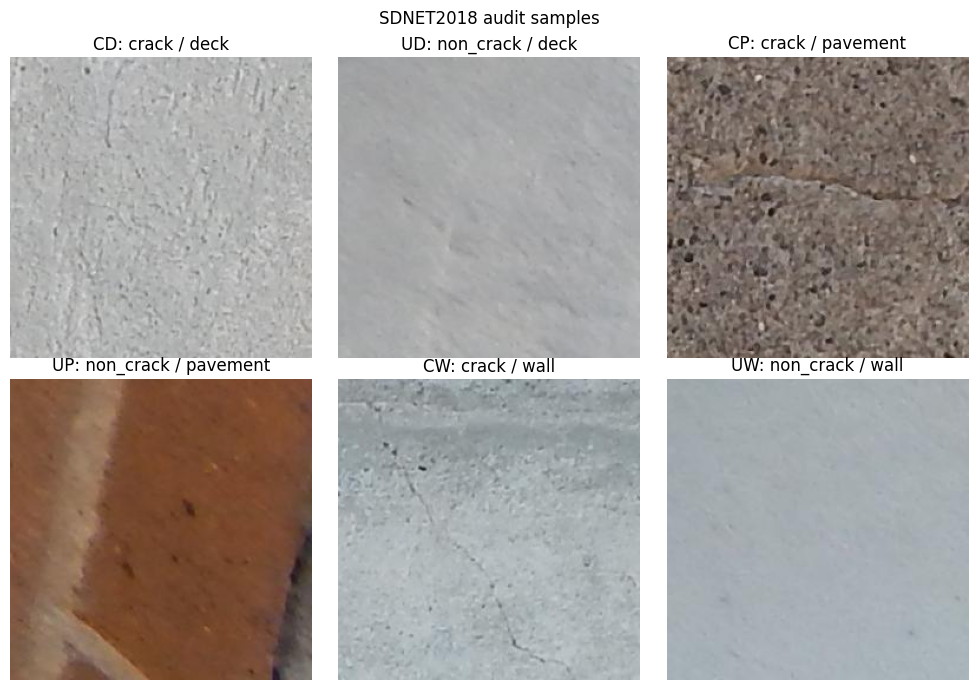

In [42]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(2, 3, figsize=(10, 7))
for axis, code in zip(axes.flat, CLASS_INFO):
    sample_row = next(row for row in eligible_by_code[code] if not row["excluded"])
    with Image.open(DATASET_ROOT / sample_row["path"]) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(f"{code}: {sample_row['class_name']} / {sample_row['surface']}")
    axis.axis("off")

figure.suptitle("SDNET2018 audit samples")
figure.tight_layout()
plt.show()

## 11. Save the Stage 2 summary

The summary separates observed facts from the unresolved parent-lineage gate.

In [43]:
summary = {
    "stage": "SDNET2018 audit and manifest",
    "official_record": OFFICIAL_RECORD_URL,
    "archive_md5": archive_md5,
    "archive_sha256": archive_sha256,
    "dataset_root": str(DATASET_ROOT.resolve()),
    "expected_counts": EXPECTED_COUNTS,
    "observed_counts": observed_counts,
    "total_images": len(rows),
    "corrupt_images": corrupt_count,
    "wrong_size_images": wrong_size_count,
    "non_rgb_images": non_rgb_count,
    "duplicate_groups": len(duplicate_groups),
    "duplicate_files_excluded": duplicate_file_count,
    "eligible_images": len(eligible_rows),
    "verified_parent_ids": parent_coverage,
    "research_split_status": (
        "parent_mapping_complete" if parent_coverage == len(eligible_rows)
        else "blocked_until_verified_parent_mapping"
    ),
    "development_images": len(development_rows),
    "development_split_basis": "tile_development_only",
    "audit_manifest": str(AUDIT_MANIFEST_PATH.resolve()),
    "development_manifest": str(DEVELOPMENT_MANIFEST_PATH.resolve()),
}

SUMMARY_PATH = OUTPUT_DIR / "stage_two_summary.json"
SUMMARY_PATH.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print(json.dumps(summary, indent=2))
print("Saved", SUMMARY_PATH.resolve())

{
  "stage": "SDNET2018 audit and manifest",
  "official_record": "https://digitalcommons.usu.edu/all_datasets/48/",
  "archive_md5": "677411e784f194422c90f52d9ed0d7c6",
  "archive_sha256": "6f304ea70f1a25e52095df3f5e98f53428b6ad6c06819ea8ba4cbf920a90f7c1",
  "dataset_root": "/content/data/SDNET2018_extracted/SDNET2018",
  "expected_counts": {
    "CD": 2025,
    "UD": 11595,
    "CP": 2608,
    "UP": 21726,
    "CW": 3851,
    "UW": 14287
  },
  "observed_counts": {
    "CD": 2025,
    "UD": 11595,
    "CP": 2608,
    "UP": 21726,
    "CW": 3851,
    "UW": 14287
  },
  "total_images": 56092,
  "corrupt_images": 0,
  "wrong_size_images": 0,
  "non_rgb_images": 0,
  "duplicate_groups": 13,
  "duplicate_files_excluded": 13,
  "eligible_images": 56079,
  "verified_parent_ids": 0,
  "research_split_status": "blocked_until_verified_parent_mapping",
  "development_images": 3600,
  "development_split_basis": "tile_development_only",
  "audit_manifest": "/content/outputs/sdnet2018_audit/audit_

## Stage 2 exit criterion

Stage 2 is complete when the checksum passes, all six class counts are reported, the full image audit finishes, the sample panel looks correctly labelled, and audit_manifest.csv, development_manifest.csv, and stage_two_summary.json exist.

The next stage may train MobileViT-XS on development_manifest.csv. Results must retain the tile_development_only warning until a complete verified parent mapping is available.